# Machine Learning Lab

## Student Information

- **Name:** Talha Abdullah Bangyal
- **Roll Number:** SU92-BAIFM-F25-002
- **Section:** BSAI-7C
- **Subject:** Machine Learning Lab
- **Lab:** 5

## Tools and Technologies

- **Programming Language:** Python
- **Environment:** Jupyter Notebook
- **Libraries:**
    - NumPy
    - Pandas
    - Matplotlib
    - Scikit-learn (as required)

# Task 1

## Question 1 - Load and Explore the data

- Load customer_purchase.csv into a table. Print it's shape and the first 10 rows.
- Print the smallest and the largest value of minuites_on_site.
- Count how many customers bought and how many did not.
- Make a scatter plot: minuites on the x-axis, bought (0 or 1) on y axis. Add axis labels and a title.
- In on sentence describe the pattern you see in the scatter plot.

## Hint: no formula needed - this question is about to looking at the data before doing any calculation

Shape: (100, 2)

First 10 rows:


,minutes_on_site,bought
0,1.8,0
1,2.4,0
2,2.6,0
3,2.9,0
4,3.0,0
5,3.7,0
6,3.7,0
7,6.2,0
8,6.4,0
9,7.5,0



Minimum minutes on site: 1.8
Maximum minutes on site: 38.8

Purchase counts:
Bought: 59
Did not buy: 41


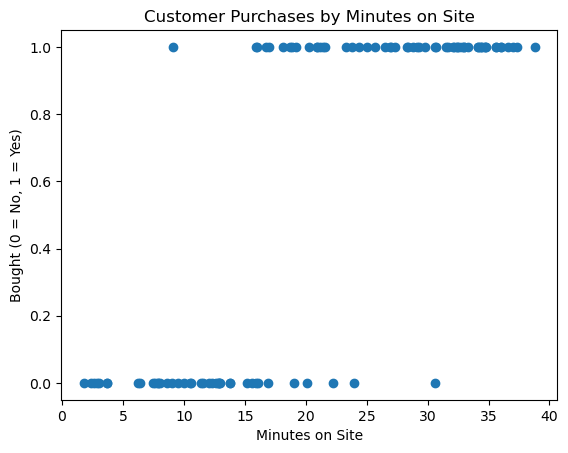

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("customer_purchase_dataset.csv")

# Display the shape of the DataFrame and the first 10 rows
print("Shape:", df.shape)
print("\nFirst 10 rows:")
display(df.head(10))

# Find the minimum and maximum values of the "minutes_on_site" column
print("\nMinimum minutes on site:", df["minutes_on_site"].min())
print("Maximum minutes on site:", df["minutes_on_site"].max())

# Count the number of customers who bought and those who did not
print("\nPurchase counts:")
print("Bought:", (df["bought"] == 1).sum())
print("Did not buy:", (df["bought"] == 0).sum())

# Create a scatter plot of "minutes_on_site" vs "bought"
plt.scatter(df["minutes_on_site"], df["bought"])
plt.xlabel("Minutes on Site")
plt.ylabel("Bought (0 = No, 1 = Yes)")
plt.title("Customer Purchases by Minutes on Site")
plt.show()

## Observation

Scatter plot aik clear pattern show karta hai: jo customers website par zyada time spend karte hain, unke purchase karne ke chances zyada hotay hain, jabke jo customers website par kam minutes spend karte hain, unke purchase na karne ke chances zyada hotay hain.

# Task 2

## Question 2 — Fit the Model

- Fit a Logistic Regression model using minutes_on_site to predict bought.
- Print theta0 and theta1.
- Print the model's training accuracy.
- In one sentence, explain what a positive theta1 tells us about minutes on site and buying.

## ​Hint (formula): z = theta0 + theta1 * minutes_on_site

In [13]:
from sklearn.linear_model import LogisticRegression

# Prepare the data for logistic regression
X = df[["minutes_on_site"]]
y = df["bought"]

# Train the logistic regression model
model = LogisticRegression()
model.fit(X, y)

# Extract the model parameters and calculate accuracy
theta0 = model.intercept_[0]
theta1 = model.coef_[0][0]
accuracy = model.score(X, y)

# Display the model parameters and training accuracy
print("Theta0:", theta0)
print("Theta1:", theta1)
print("Training accuracy:", accuracy)

Theta0: -5.745490255597751
Theta1: 0.3194735678718318
Training accuracy: 0.9


## Observation

A positive theta1 ka matlab hai ke customers jitna zyada time website par spend karte hain, unke purchase karne ke chances utne hi zyada hotay hain.

# Task 3

## Question 3 — Raw Score for Three Customers

​Calculate the raw score (z) for three customers: one who spent 5 minutes, one who spent 18 minutes, and one who spent 35 minutes.

- Print all three z values, clearly labeled by minutes.
- Which of the three has a raw score closest to 0? Why does that make sense?

## Hint (Formula): z = theta0 + theta1 * minutes_on_site

In [14]:
# Calculate the raw scores (z-values) for specific minutes on site
minutes = [5, 18, 35]
z_values = {m: theta0 + theta1 * m for m in minutes}

# Display the raw scores for the specified minutes
for m, z in z_values.items():
    print(f"z for {m} minutes: {z:.4f}")

# Find the minute with the raw score closest to 0
closest_minutes = min(z_values, key=lambda m: abs(z_values[m]))

# Display the minute with the raw score closest to 0
print(
    f"\nThe raw score closest to 0 is for {closest_minutes} minutes "
    f"(z = {z_values[closest_minutes]:.4f})."
)

# This indicates the point where the model is most uncertain about the prediction.
print("\nThis makes sense because it is closest to the model's decision boundary.")

z for 5 minutes: -4.1481
z for 18 minutes: 0.0050
z for 35 minutes: 5.4361

The raw score closest to 0 is for 18 minutes (z = 0.0050).

This makes sense because it is closest to the model's decision boundary.


# Task 4

## Question 4 — Build the Sigmoid Function
- Write your own function called sigmoid that takes a number z and returns the probability.  
- Test your function with z = -5, z = 0, and z = 5. Print the three answers.  
- In 2 sentences, describe what you notice about the three answers. Can the answer ever be below 0 or above 1?  
​
## Hint (formula): sigmoid(z) = 1 / (1 + e^-z)
## In Python, e^{-z} is written as np.exp(-z) (after import numpy as np).

In [15]:
import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Display the sigmoid values for -5, 0, and 5
for value in [-5, 0, 5]:
    print(f"sigmoid({value}) = {sigmoid(value):.4f}")

sigmoid(-5) = 0.0067
sigmoid(0) = 0.5000
sigmoid(5) = 0.9933


## Observation

Jab z negative hota hai, to sigmoid ki value 0 ke qareeb hoti hai. Jab z = 0 hota hai, to iski value 0.5 hoti hai. Aur jab z positive hota hai, to sigmoid ki value 1 ke qareeb hoti hai. Sigmoid ka output kabhi bhi 0 se kam ya 1 se zyada nahi ho sakta.

# Task 5

## Question 5 — Probabilities for the Three Customers

​Using your z values from Question 3 and your sigmoid function, calculate the probability of buying for the 5, 18, and 35 minute customers.

- Print all three probabilities, labeled by minutes.  
- Which customer is closest to a 50% chance of buying?  
- Which customer is most likely to buy?  
​
## Hint (formula): sigmoid(z) = 1 / (1 + e^-z)

In [16]:
# Calculate the probabilities of buying for the specified minutes
probabilities = {m: sigmoid(z_values[m]) for m in minutes}

# Display the probabilities of buying for the specified minutes
for m, probability in probabilities.items():
    print(f"Probability of buying for {m} minutes: {probability:.4f}")

# Find the minute with the probability closest to 50% and the minute with the highest probability of buying
closest_to_50 = min(probabilities, key=lambda m: abs(probabilities[m] - 0.5))
most_likely = max(probabilities, key=probabilities.get)

# Display the results for closest to 50% chance and most likely to buy
print(f"\nClosest to a 50% chance: {closest_to_50} minutes")
print(f"Most likely to buy: {most_likely} minutes")

Probability of buying for 5 minutes: 0.0155
Probability of buying for 18 minutes: 0.5013
Probability of buying for 35 minutes: 0.9957

Closest to a 50% chance: 18 minutes
Most likely to buy: 35 minutes


# Task 6

## ​Question 6 — Final Prediction and Summary Table

​Using your probabilities from Question 5, decide the predicted outcome (Buy or No buy) for each customer. 

- Print the predicted outcome for all three customers.  
- Put your results from Questions 3, 5, and 6 into one small table with these columns: minutes, z, probability, predicted outcome.  

## Hint (rule): If probability >= 0.5 -> Buy. If probability < 0.5 -> No buy.

In [ ]:
# Create a summary table of the predictions
summary_data = []

# Calculate the predicted outcomes for the specified minutes
for m in [5, 18, 35]:
    # Calculate the raw score and probability
    z = theta0 + (theta1 * m)
    prob = sigmoid(z)

    # Predict outcome
    prediction = "Buy" if prob >= 0.5 else "No buy"

    # Append the data to the summary list
    summary_data.append({
        "minutes": m,
        "z": round(z, 4),
        "probability": round(prob, 4),
        "predicted outcome": prediction
    })

# Convert the summary data into a DataFrame
summary_df = pd.DataFrame(summary_data)

# Display the final prediction summary table
print("--- Final Prediction Summary Table ---")
display(summary_df)

--- Final Prediction Summary Table ---


,minutes,z,probability,predicted outcome
0,5,-4.1481,0.0155,No buy
1,18,0.0050,0.5013,Buy
2,35,5.4361,0.9957,Buy


# Task 7

## Question 7 — The Decision Boundary

Calculate the exact decision boundary for this model.
 
- For each of your three customers (5, 18, and 35 minutes), say whether they are below or above the boundary.
- Confirm this matches the predicted outcomes from Question 6. Then, in one sentence, explain why the 18-minute customer is a.

In [17]:
# Calculate the decision boundary
decision_boundary = -theta0 / theta1

# Display the decision boundary
print(f"Exact Decision Boundary: {decision_boundary:.4f} minutes")

# Determine whether each customer is above or below the decision boundary
for m in [5, 18, 35]:
    position = "above" if m > decision_boundary else "below"

    print(f"Customer at {m} minutes is {position} the decision boundary.")

Exact Decision Boundary: 17.9842 minutes
Customer at 5 minutes is below the decision boundary.
Customer at 18 minutes is above the decision boundary.
Customer at 35 minutes is above the decision boundary.


## Observation

18 minutes wala customer close call hai kyun ke uska website par guzara gaya waqt decision boundary ke bohat qareeb hai, jis ki wajah se purchase karne ki probability taqreeban 50% hai. Iska matlab hai ke waqt mein thori si tabdeeli se predicted outcome "No buy" se "Buy" mein change ho sakta hai.

# Task 8

## Question 8 — Close to the Boundary

For a customer who spends *exactly the boundary number of minutes*, calculate $z$ and the probability.

- Calculate the probability for a customer who spends *1 minute less* than the boundary, and for one who spends.
- In 2 sentences, explain what happens to the probability and to the predicted outcome as minutes cross the boundary.

In [18]:
# Calculate the z-value and probability at the decision boundary
z_bound = theta0 + (theta1 * decision_boundary)
prob_bound = sigmoid(z_bound)

# Display the z-value and probability at the decision boundary
print(f"--- At Boundary ({decision_boundary:.2f} minutes) ---")
print(f"z: {z_bound:.4f}")
print(f"Probability: {prob_bound:.4f}")

# One minute less
mins_less = decision_boundary - 1
# Calculate the z-value and probability for one minute less than the decision boundary
z_less = theta0 + (theta1 * mins_less)
# Calculate the probability for one minute less than the decision boundary
prob_less = sigmoid(z_less)
# Determine the prediction based on the probability
pred_less = "Buy" if prob_less >= 0.5 else "No buy"

# Display the results for one minute less than the decision boundary
print(f"--- One Minute Less ({mins_less:.2f} minutes) ---")
print(f"z: {z_less:.4f}")
print(f"Probability: {prob_less:.4f}")
print(f"Prediction: {pred_less}")

# One minute more
mins_more = decision_boundary + 1
# Calculate the z-value and probability for one minute more than the decision boundary
z_more = theta0 + (theta1 * mins_more)
# Calculate the probability for one minute more than the decision boundary
prob_more = sigmoid(z_more)
# Determine the prediction based on the probability
pred_more = "Buy" if prob_more >= 0.5 else "No buy"

# Display the results for one minute more than the decision boundary
print(f"\n--- One Minute More ({mins_more:.2f} minutes) ---")
print(f"z: {z_more:.4f}")
print(f"Probability: {prob_more:.4f}")
print(f"Prediction: {pred_more}")

--- At Boundary (17.98 minutes) ---
z: 0.0000
Probability: 0.5000
--- One Minute Less (16.98 minutes) ---
z: -0.3195
Probability: 0.4208
Prediction: No buy

--- One Minute More (18.98 minutes) ---
z: 0.3195
Probability: 0.5792
Prediction: Buy


## Observation

Jab website par guzara gaya waqt decision boundary ko cross karta hai, to purchase karne ki probability 50% se kam se 50% se zyada ho jati hai. Is liye predicted outcome "No buy" se change ho kar "Buy" ho jata hai.

# Task 9

## Question 9 — Check Real Customers in the Dataset

In [19]:
# Vectorized calculation for all 100 customers using float-casted parameters
z_all = theta0 + (theta1 * df['minutes_on_site'])
# Calculate the probabilities and predictions for all customers
probs_all = sigmoid(z_all)
# Convert probabilities to binary predictions
preds_all = (probs_all >= 0.5).astype(int)

# Calculate the overall accuracy of the model on the entire dataset
correct_total = (preds_all == df['bought']).sum()
# Calculate the total number of customers and the overall accuracy
total_customers = len(df)
# Calculate the overall accuracy of the model on the entire dataset
accuracy_overall = (correct_total / total_customers) * 100

# Display the overall dataset evaluation
print(f"--- Overall Dataset Evaluation ---")
print(f"Total Customers: {total_customers}")
print(f"Correct Predictions: {correct_total}")
print(f"Overall Accuracy: {accuracy_overall:.2f}%")

--- Overall Dataset Evaluation ---
Total Customers: 100
Correct Predictions: 90
Overall Accuracy: 90.00%


# Task 10

## Question 10 — Counting Correct Predictions for All 100 Customers

In [22]:
# Check the model's performance on specific rows of the dataset
rows_to_check = [0, 16, 50, 75]
q9_results = []

# Check the model's performance on specific rows of the dataset
print("--- Checking Specific Dataset Rows ---")
# For each row, calculate the z-value, probability, and prediction
for r in rows_to_check:
    # Extract the minutes on site and actual purchase value for the current row
    mins = df.loc[r, 'minutes_on_site']
    # Extract the actual purchase value for the current row
    actual = df.loc[r, 'bought']
    # Calculate the z-value, probability, and prediction for the current row
    z = theta0 + (theta1 * mins) 
    # Calculate the probability and prediction based on the z-value
    prob = sigmoid(z)
    # Determine the prediction based on the probability
    pred = 1 if prob >= 0.5 else 0
    # Check if the prediction is correct
    correct = (pred == actual)
    
    q9_results.append({
        "row": r,
        "minutes": mins,
        "actual": actual,
        "z": round(z, 4),
        "probability": round(prob, 4),
        "prediction": pred,
        "correct": correct
    })
    print(f"Row {r:2d} | Minutes: {mins:4.1f} | Actual: {actual} | Predicted: {pred} | Correct: {correct}")

# Create a DataFrame to display the results of the specific rows checked
q9_df = pd.DataFrame(q9_results)
display(q9_df)

--- Checking Specific Dataset Rows ---
Row  0 | Minutes:  1.8 | Actual: 0 | Predicted: 0 | Correct: True
Row 16 | Minutes:  9.1 | Actual: 1 | Predicted: 0 | Correct: False
Row 50 | Minutes: 21.2 | Actual: 1 | Predicted: 1 | Correct: True
Row 75 | Minutes: 32.1 | Actual: 1 | Predicted: 1 | Correct: True


,row,minutes,actual,z,probability,prediction,correct
0,0,1.8,0,-5.1704,0.0056,0,True
1,16,9.1,1,-2.8383,0.0553,0,False
2,50,21.2,1,1.0273,0.7364,1,True
3,75,32.1,1,4.5096,0.9891,1,True


# Task 11

## Question 11 — Verify with scikit-learn

In [23]:
# Select the exact rows from Question 9
subset_df = df.loc[[0, 16, 50, 75], ["minutes_on_site"]]

# Create a compatibility alias so the older name works too
log_reg = model

# Get scikit-learn predictions and probabilities
sk_probs = log_reg.predict_proba(subset_df)
sk_preds = log_reg.predict(subset_df)

print("--- Scikit-Learn Verification ---")
for i, r in enumerate([0, 16, 50, 75]):
    print(
        f"Row {r:2d} | Sklearn Prob (No buy, Buy): "
        f"[{sk_probs[i][0]:.4f}, {sk_probs[i][1]:.4f}] | Sklearn Pred: {sk_preds[i]}"
    )

--- Scikit-Learn Verification ---
Row  0 | Sklearn Prob (No buy, Buy): [0.9944, 0.0056] | Sklearn Pred: 0
Row 16 | Sklearn Prob (No buy, Buy): [0.9447, 0.0553] | Sklearn Pred: 0
Row 50 | Sklearn Prob (No buy, Buy): [0.2636, 0.7364] | Sklearn Pred: 1
Row 75 | Sklearn Prob (No buy, Buy): [0.0109, 0.9891] | Sklearn Pred: 1


## Observation

Checking your manual calculations against a trusted library like scikit-learn is useful because it validates that your mathematical formulas, parameter extractions, and coding logic are implemented correctly without hidden bugs.

# Task 12

## Question 12 — Draw the Whole Model

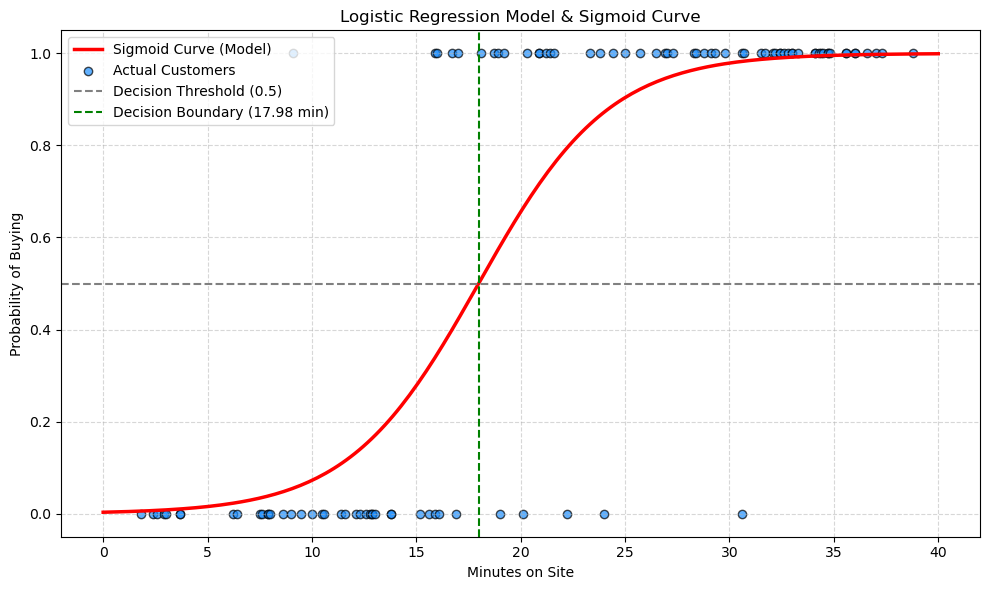

In [24]:
# a) Create 200 evenly spaced minutes from 0 to 40
minutes_range = np.linspace(0, 40, 200)

# b) Calculate sigmoid probabilities for the range
z_range = theta0 + (theta1 * minutes_range)
probs_range = sigmoid(z_range)

# c) Plotting the full model
plt.figure(figsize=(10, 6))

# Plot the sigmoid curve
plt.plot(minutes_range, probs_range, color='red', linewidth=2.5, label='Sigmoid Curve (Model)')

# Plot the 100 actual customers as dots
plt.scatter(df['minutes_on_site'], df['bought'], color='dodgerblue', edgecolors='k', alpha=0.7, label='Actual Customers')

# Horizontal line at probability = 0.5
plt.axhline(0.5, color='gray', linestyle='--', label='Decision Threshold (0.5)')

# Vertical line at decision boundary
plt.axvline(decision_boundary, color='green', linestyle='--', label=f'Decision Boundary ({decision_boundary:.2f} min)')

# Labels, title, and legend
plt.xlabel('Minutes on Site')
plt.ylabel('Probability of Buying')
plt.title('Logistic Regression Model & Sigmoid Curve')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Observation

The plot clearly demonstrates an S-shaped (sigmoid) transition where the probability of buying starts near 0 for visitors spending very little time on the site and smoothly increases toward 1 as time on site grows[cite: 5]. The decision boundary at roughly 18 minutes acts as the exact tipping point where the probability crosses 50%, cleanly dividing customers into predicted "No buy" and "Buy" categories.